# Figure 2: Value of Staged Infrastructure Planning


In [1]:
file ='../Figures'


# import data

import pandas as pd
import os
import numpy as np

# function that creates dataframe from list of files in a path
def create_dataframe(path, tag):
# get all files in the path
    files = os.listdir(path)

    # create a dictionary to store all dataframes
    dfs = {}

    for file in files:
        if file.endswith('.csv'):
            # read the csv file
            df = pd.read_csv(path+file)

            if tag == 'results':
                WWTP = file.split('results_')[1]
                WWTP = WWTP.split('.csv')[0]
                if 'econ' not in WWTP:
                    dfs[WWTP] = df
            
            # if file includes econ in name
            elif 'econ' in file and tag in file:
                # create string with only the characters after "results_econ_"
                WWTP= file.split('results_econ_')[1]
                WWTP = WWTP.split('.csv')[0]
                dfs[WWTP] = df

            # if file includes flow in name
            elif 'flow' in file and tag in file:
                # create string with only the characters after "results_flow_"
                WWTP= file.split('results_flow_')[1]
                WWTP = WWTP.split('.csv')[0]
                dfs[WWTP] = df
                
    return dfs
                    

def create_df(WWTP, dfs):
    df = dfs[WWTP]
    df.rename(columns={df.columns[0]: 'Datetime'}, inplace=True)
    df.Datetime = pd.to_datetime(df.Datetime)
    return df


In [2]:
path_case_1 = '../Results/Non_Staged/No_coordination/'
path_case_2 = '../Results/Staged/No_coordination/'
path_case_5 = '../Results/Non_Staged/Full_coordination/'
path_case_6 = '../Results/Staged/Full_coordination/'

dfs_econ_case_1 = create_dataframe(path_case_1, 'econ')
dfs_econ_case_2 = create_dataframe(path_case_2, 'econ')

dfs_results_case_1 = create_dataframe(path_case_1, 'results')
dfs_results_case_2 = create_dataframe(path_case_2, 'results')

dfs_flow_case_1 = create_dataframe(path_case_1, 'flow')
dfs_flow_case_2 = create_dataframe(path_case_2, 'flow')
dfs_flow_case_5 = create_dataframe(path_case_5, 'flow')
dfs_flow_case_6 = create_dataframe(path_case_6, 'flow')


In [3]:
path_sum_case_1 = '../Results/Non_Staged/No_coordination_summary.csv'
path_sum_case_2 = '../Results/Staged/No_coordination_summary.csv'

df_case_1 = pd.read_csv(path_sum_case_1)
df_case_2 = pd.read_csv(path_sum_case_2)


In [11]:
import matplotlib.pyplot as plt

#colors = ['green', 'red', 'purple', 'black', 'yellow', 'pink', 'brown', 'grey']

#L_upgrades = ['SS', 'L2', 'L2upg3', 'L3']
#colors = {'L3':'black', 'L2':'red', 'L2upg3':'green', 'SS': 'pink'}
L_upgrades = ['SS', 'L2', 'L3']
colors = {'L3': '#726DA8', 'L2': '#484538', 'SS': '#B9CC57', 'total': '#EB5E28'}
upg_leg = {'L3':'Level 3', 'L2':'Level 2', 'SS': 'Sidestream treatment'}
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
leg_size = 6
line_wid = 0.75
bord_wid = 2

WWTP = 'SJSC'
def plot_WWTP_results(WWTP, lim_2, lim_3, fig_tag, fig_tag2, case):
    tags = ['_per_removal', '_opex', '_capex']
    y_label = ['TIN Removal\n(%)', 'Opex\n(NPV $mil/year)', 'Capex\n(NPV $mil)']

    fig, axs_b = plt.subplots(3, 1, figsize=(130/25.4, 90/25.4))

    # plot percent removal
    tag = '_per_removal'

    if case == 'S-NC':
        df = create_df(WWTP, dfs_results_case_2)
        
    elif case == 'NS-NC':
        df = create_df(WWTP, dfs_results_case_1)
        
    
    for L in L_upgrades:
        axs_b[0].step(df.Datetime, df[L+ tag], '-', color = colors[L],label = upg_leg[L], where='post', linewidth = line_wid)
        idx = df[df['Datetime'] == '2034-01-01'].index[0]
        if L == L_upgrades[-1]:
            axs_b[0].plot(df.Datetime[idx:], df[L + '_per_lim'][idx:], '--', color = 'black', label= 'Upgrade removal limit', linewidth = line_wid)

        axs_b[0].plot(df.Datetime[idx:], df[L + '_per_lim'][idx:], '--', color = colors[L], label = '', linewidth = line_wid)
        axs_b[0].set_ylabel(y_label[0], **hfont)

    axs_b[0].legend(loc = 'upper left', frameon=False, bbox_to_anchor=(0, 0.8),prop={'family':'Helvetica', 'size':leg_size})
    axs_b[0].set_xticks([df.Datetime[t] for t in range(0, len(df.Datetime), 12*5)])
    axs_b[0].set_xticklabels([], **hfont_ticks)
    axs_b[0].set_ylim(0, 100)

    # Plot economic parameters
    # plot operating costs:

    if case == 'S-NC':
        df = create_df(WWTP, dfs_econ_case_2)
    elif case == 'NS-NC':
        df = create_df(WWTP, dfs_econ_case_1)

    for L in L_upgrades:
            axs_b[1].step(df.Datetime, np.append(df[L+ tags[1]][:-1], np.array(df[L+ tags[1]])[-2]), '-', color = colors[L], where='post', linewidth = line_wid)
    axs_b[1].set_ylabel(y_label[1], **hfont)
    opex_sum = np.array([sum(df[L+ '_opex'] for L in L_upgrades)][0].T)
    axs_b[1].step(df.Datetime, np.append(opex_sum[:-1],opex_sum[-2]), linestyle = 'dashdot', color = colors['total'],label = 'Total opex',  where='post', linewidth = line_wid)
    axs_b[1].legend(loc = 'upper left', frameon=False, bbox_to_anchor=(0, 0.8), prop={'family':'Helvetica', 'size':leg_size})
    axs_b[1].set_xticklabels([])
    axs_b[1].set_xlim(axs_b[0].get_xlim())
    axs_b[1].set_xticks([df.Datetime[t] for t in range(0, len(df.Datetime), 5)])
    axs_b[1].set_xticklabels([], **hfont_ticks)
    axs_b[1].set_ylim(0, lim_2)

    for L in L_upgrades:
        cum_capex = []
        cum_capex_value = 0
        for j, year in enumerate(df.Datetime):
            cum_capex_value += sum(df.loc[j, L + tags[2]] for L in L_upgrades)
            cum_capex.append(cum_capex_value)
        axs_b[2].step(df.Datetime, df[L+ tags[2]], '-', color = colors[L], label = '' , where='post', linewidth = line_wid)
        
    axs_b[2].step(df.Datetime, cum_capex, linestyle = 'dashdot', color = colors['total'],label = 'Cumulative capex',  where='post', linewidth = line_wid)
    axs_b[2].legend(loc = 'upper left', frameon=False, bbox_to_anchor=(0, 0.8), prop={'family':'Helvetica', 'size':leg_size})
    if WWTP == 'Palo Alto':
        axs_b[2].legend(loc = 'upper left', frameon=False, bbox_to_anchor=(0.7, 0.25), prop={'family':'Helvetica', 'size':leg_size})
    if WWTP == 'SJSC' and fig_tag == 'SI':
        axs_b[2].legend(loc = 'upper left', frameon=False, bbox_to_anchor=(0.7, 0.25), prop={'family':'Helvetica', 'size':leg_size})
    
    axs_b[2].set_xlabel('Year', **hfont)
    axs_b[2].set_xticks([df.Datetime[t] for t in range(0, len(df.Datetime), 5)])
    axs_b[2].set_xticklabels([df.Datetime[t].strftime('%Y') for t in range(0, len(df.Datetime), 5)], **hfont_ticks)
    axs_b[2].set_ylabel(y_label[2], **hfont)
    axs_b[2].set_ylim(0, lim_3)

    # change limits of first plot to adjust the scale
    axs_b[0].set_xlim(axs_b[1].get_xlim())
    axs_b[0].set_xticks([df.Datetime[t] for t in range(0, len(df.Datetime), 5)])
    axs_b[0].set_xticklabels([])


    # Align y-labels
    x_label_coord = -0.06  # Adjust this value to control the x position of all y-labels
    fig_labels = ['i', 'ii', 'iii']
    for i,ax in enumerate(axs_b):
        ax.yaxis.set_label_coords(x_label_coord, 0.5)  # Align at x=-0.1, center vertically (y=0.5)
        ax.text(0.02, 0.9, fig_labels[i], transform=ax.transAxes, fontsize=leg_size, fontweight='bold', va='top', ha='left')
        ax.xaxis.set_ticks_position('both')
        ax.tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')
        ax.set_xlim(axs_b[1].get_xlim())
        ax.tick_params(axis="both", width=line_wid, length=bord_wid)
        for spine in ax.spines.values():
            spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)

    fig.tight_layout()
    if fig_tag == 'main':
        fig.savefig(file + "/Fig_2b.svg", format="svg", dpi=300)
    if fig_tag == 'SI':
        fig.savefig(file + "/SI/" + fig_tag2 + ".svg", format="svg", dpi=300)

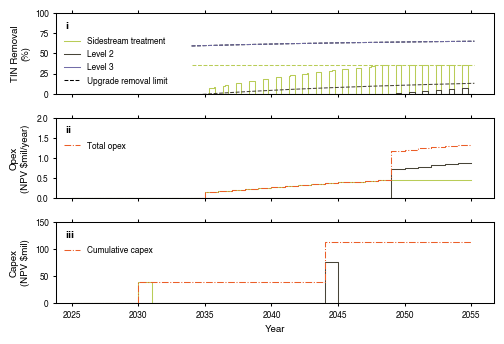

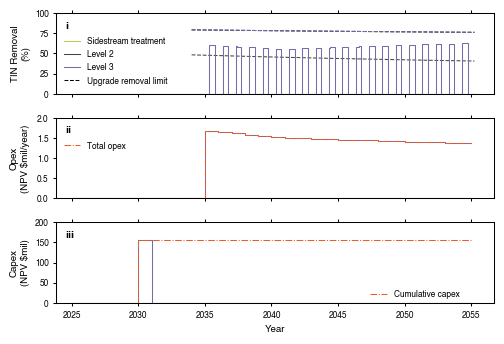

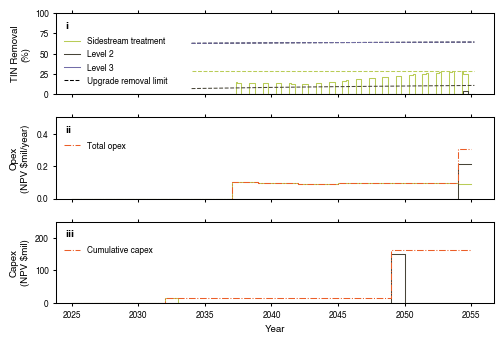

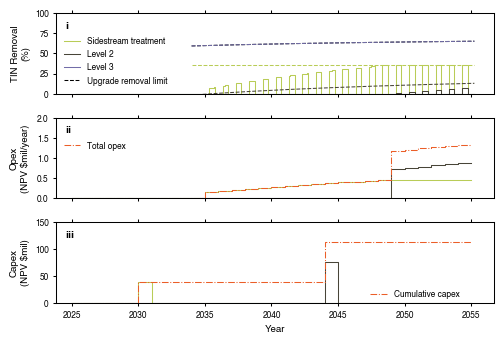

In [13]:
plot_WWTP_results('SJSC', lim_2=2, lim_3=150, fig_tag='main', fig_tag2 = '', case ='S-NC')
plot_WWTP_results('Palo Alto', lim_2=2, lim_3=200, fig_tag='SI', fig_tag2= 'S3', case ='S-NC')
plot_WWTP_results('Sunnyvale', lim_2 = 0.5, lim_3 = 250, fig_tag='SI', fig_tag2 = 'S2', case ='S-NC')

plot_WWTP_results('SJSC', lim_2=2, lim_3=150, fig_tag='SI', fig_tag2 = 'S1', case ='NS-NC')
#plot_WWTP_results('Palo Alto', lim_2=2, lim_3=200, fig_tag='SI', fig_tag2 = '', case ='NS-NC')
#plot_WWTP_results('Sunnyvale', lim_2 = 0.5, lim_3 = 250, fig_tag='SI', fig_tag2 = '',case ='NS-NC')

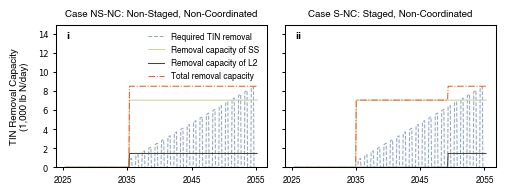

In [8]:
# Plot 3a

WWTP = 'SJSC'
L_upgrades = ['SS', 'L2', 'L3']
colors = {'L3': '#726DA8', 'L2': '#484538', 'SS': '#CAD49D', 'total': '#EB5E28', 'required': '#8EA8C3'}
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
leg_size = 6
line_wid = 0.75
bord_wid = 2

fig, axs = plt.subplots(1, 2, figsize=(130/25.4, 52/25.4))

df_1 = create_df(WWTP, dfs_results_case_1)
df_2 = create_df(WWTP, dfs_results_case_2)
df = create_df(WWTP, dfs_econ_case_2)

axs[0].plot(df_1.Datetime, df_1['Required_removal']/1000  , '--', color=colors['required'], label = 'Required TIN removal', linewidth = line_wid)
axs[1].plot(df_2.Datetime, df_2['Required_removal']/1000  , '--', color=colors['required'], label = '', linewidth = line_wid)
for L in L_upgrades:
    if sum(df_1[L + '_u']) == 1:
        axs[0].plot(df_1.Datetime, [df_1[L + '_x_max'] * df_1[L + '_b']][0].T/1000,'-', color = colors[L],label = 'Removal capacity of ' + L, linewidth = line_wid)
    if sum(df_2[L + '_u']) == 1:
        axs[1].plot(df_2.Datetime, [df_2[L + '_x_max'] * df_2[L + '_b']][0].T/1000,'-', color = colors[L],label = '', linewidth = line_wid)
axs[0].plot(df_1.Datetime, [sum(df_1[L + '_x_max'] * df_1[L + '_b'] for L in L_upgrades)][0].T/1000, linestyle = 'dashdot', color=colors['total'], label = 'Total removal capacity', linewidth = line_wid)
axs[1].plot(df_2.Datetime, [sum(df_2[L + '_x_max'] * df_2[L + '_b'] for L in L_upgrades)][0].T/1000, linestyle = 'dashdot', color=colors['total'], label = '', linewidth = line_wid)


axs[0].set_ylabel('TIN Removal Capacity\n(1,000 lb N/day)', **hfont)
axs[0].set_title('Case NS-NC: Non-Staged, Non-Coordinated', **hfont)
axs[1].set_ylim([0,15])
axs[1].set_title('Case S-NC: Staged, Non-Coordinated', **hfont)

# set x and y limits for plot i
axs[0].set_ylim(axs[1].get_ylim())
axs[0].set_xlim(axs[1].get_xlim())
axs[0].set_xticks([df.Datetime[t] for t in range(0, len(df.Datetime), 10)])
axs[0].set_xticklabels([df.Datetime[t].strftime('%Y') for t in range(0, len(df.Datetime), 10)], **hfont_ticks)
axs[0].legend(loc = 'upper right', frameon=False, prop={'family':'Helvetica', 'size':leg_size})

# set x and y limits for plot ii
axs[1].set_yticklabels([])
axs[1].set_xlim(axs[1].get_xlim())
axs[1].set_xticks([df.Datetime[t] for t in range(0, len(df.Datetime), 10)])
axs[1].set_xticklabels([df.Datetime[t].strftime('%Y') for t in range(0, len(df.Datetime), 10)], **hfont_ticks)

  # Adjust this value to control the x position of all y-labels
fig_labels = ['i', 'ii']
for i,ax in enumerate(axs):
    ax.text(0.05, 0.95, fig_labels[i], transform=ax.transAxes, fontsize=leg_size, fontweight='bold', va='top', ha='left')
    ax.tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=leg_size)
    for spine in ax.spines.values():
        spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)

axs[0].yaxis.set_label_coords(-0.125, 0.5)  # Align at x=-0.1, center vertically (y=0.5)

plt.tight_layout()
fig.savefig(file + "/Fig_2a.svg", format="svg", dpi=300)

SJSC
     Total opex savings= 0.0
     Total capex savings= 24.0
     Total cost savings= 24.0
Sunnyvale
     Total opex savings= 0.0
     Total capex savings= 60.0
     Total cost savings= 60.0
Palo Alto
     Total opex savings= 0.0
     Total capex savings= 0.0
     Total cost savings= 0.0
Percent capital cost to total cost for staged: 91 %
Percent capital cost to total cost for non-staged: 92 %


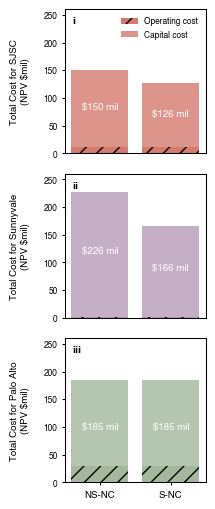

In [9]:
# plot Value of adaptive planning
import matplotlib.pyplot as plt
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
lab_size = 7
leg_size = 6
line_wid = 0.75
bord_wid = 2
colors = ['#D57A6E','#B79BB8', '#A3B89C']


ind = ['NS-NC', 'S-NC']
ind_tick = np.arange(len(ind))

WWTPs = ['SJSC', 'Sunnyvale', 'Palo Alto']
df_results_opex = pd.DataFrame(index=WWTPs, columns=['Non_staged', 'Staged'])
df_results_capex = pd.DataFrame(index=WWTPs, columns=['Non_staged', 'Staged'])

for WWTP in WWTPs:
    df_results_opex.loc[WWTP, 'Non_staged'] = df_case_1[df_case_1['Abbreviation'] == WWTP]['Total_opex'].values[0]
    df_results_opex.loc[WWTP, 'Staged'] = df_case_2[df_case_2['Abbreviation'] == WWTP]['Total_opex'].values[0]
    df_results_capex.loc[WWTP, 'Non_staged'] = df_case_1[df_case_1['Abbreviation'] == WWTP]['Total_capex'].values[0]
    df_results_capex.loc[WWTP, 'Staged'] = df_case_2[df_case_2['Abbreviation'] == WWTP]['Total_capex'].values[0]
    

fig, axs = plt.subplots(len(WWTPs), 1, figsize=(60/25.4, 132/25.4))
ind_offset = [-0.2, 0, 0.2]
for i in range(len(WWTPs)):
    axs[i].bar(ind_tick, df_results_opex.loc[WWTPs[i]].values, label = 'Operating cost' , color=colors[i], hatch = '//')
    bars = axs[i].bar(ind_tick , df_results_capex.loc[WWTPs[i]].values , label = 'Capital cost', color=colors[i], alpha=0.8, bottom = df_results_opex.loc[WWTPs[i]].values)
    for a,bar in enumerate(bars):
        yval = df_results_opex.loc[WWTPs[i]].values[a] + df_results_capex.loc[WWTPs[i]].values[a]
        axs[i].text(bar.get_x() + bar.get_width()/2.0, yval - yval/2, '$' + str(int(round(yval,0))) + ' mil', va='bottom', ha='center', color='white', fontsize=lab_size, font='Helvetica')
    
    #remove xticks
    axs[i].set_xticks([])
    y_title = 'Total Cost for '+ WWTPs[i] + '\n(NPV $mil)'
    axs[i].set_ylabel(y_title, **hfont)
    axs[i].tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')

plt.xticks(ind_tick, ind, **hfont) 

for WWTP in WWTPs:
    print(WWTP)
    print('     Total opex savings=', np.round(df_results_opex.Non_staged[WWTP]-df_results_opex.Staged[WWTP]))
    print('     Total capex savings=', np.round(df_results_capex.Non_staged[WWTP]-df_results_capex.Staged[WWTP]))
    print('     Total cost savings=', np.round(df_results_opex.Non_staged[WWTP] + df_results_capex.Non_staged[WWTP] - df_results_opex.Staged[WWTP] - df_results_capex.Staged[WWTP]))
print('Percent capital cost to total cost for staged:', round(sum(df_results_capex.Staged)/(sum(df_results_opex.Staged) + sum(df_results_capex.Staged))*100), '%')
print('Percent capital cost to total cost for non-staged:', round(sum(df_results_capex.Non_staged)/(sum(df_results_opex.Non_staged) + sum(df_results_capex.Non_staged))*100), '%')

x_label_coord = -0.25  # Adjust this value to control the x position of all y-labels
axs[0].legend(loc="upper right", ncol=1, frameon=False, prop={'family':'Helvetica', 'size':leg_size})
fig_labels = ['i', 'ii', 'iii']
ind_lab = [0.95, 0.95, 0.95]
for i,ax in enumerate(axs):
    ax.yaxis.set_label_coords(x_label_coord, 0.5)  # Align at x=-0.1, center vertically (y=0.5)
    ax.text(0.05, ind_lab[i], fig_labels[i], transform=ax.transAxes, fontsize=leg_size, fontweight='bold', va='top', ha='left')
    ax.tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=leg_size)
    ax.tick_params(axis='x', labelsize=lab_size)
    for spine in ax.spines.values():
        spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)
    ax.set_ylim(0, 260)

fig.tight_layout()
fig.savefig(file + "/Fig_2c.svg", bbox_inches="tight", format="svg", dpi=300)